# Incoherent lens imaging of a USAF source

A circular lens forms an image of an extended USAF source on a nearby monitor. Each source point emits independently, so we add intensities using the paper's finite-monitor approximation, Eq. (24).


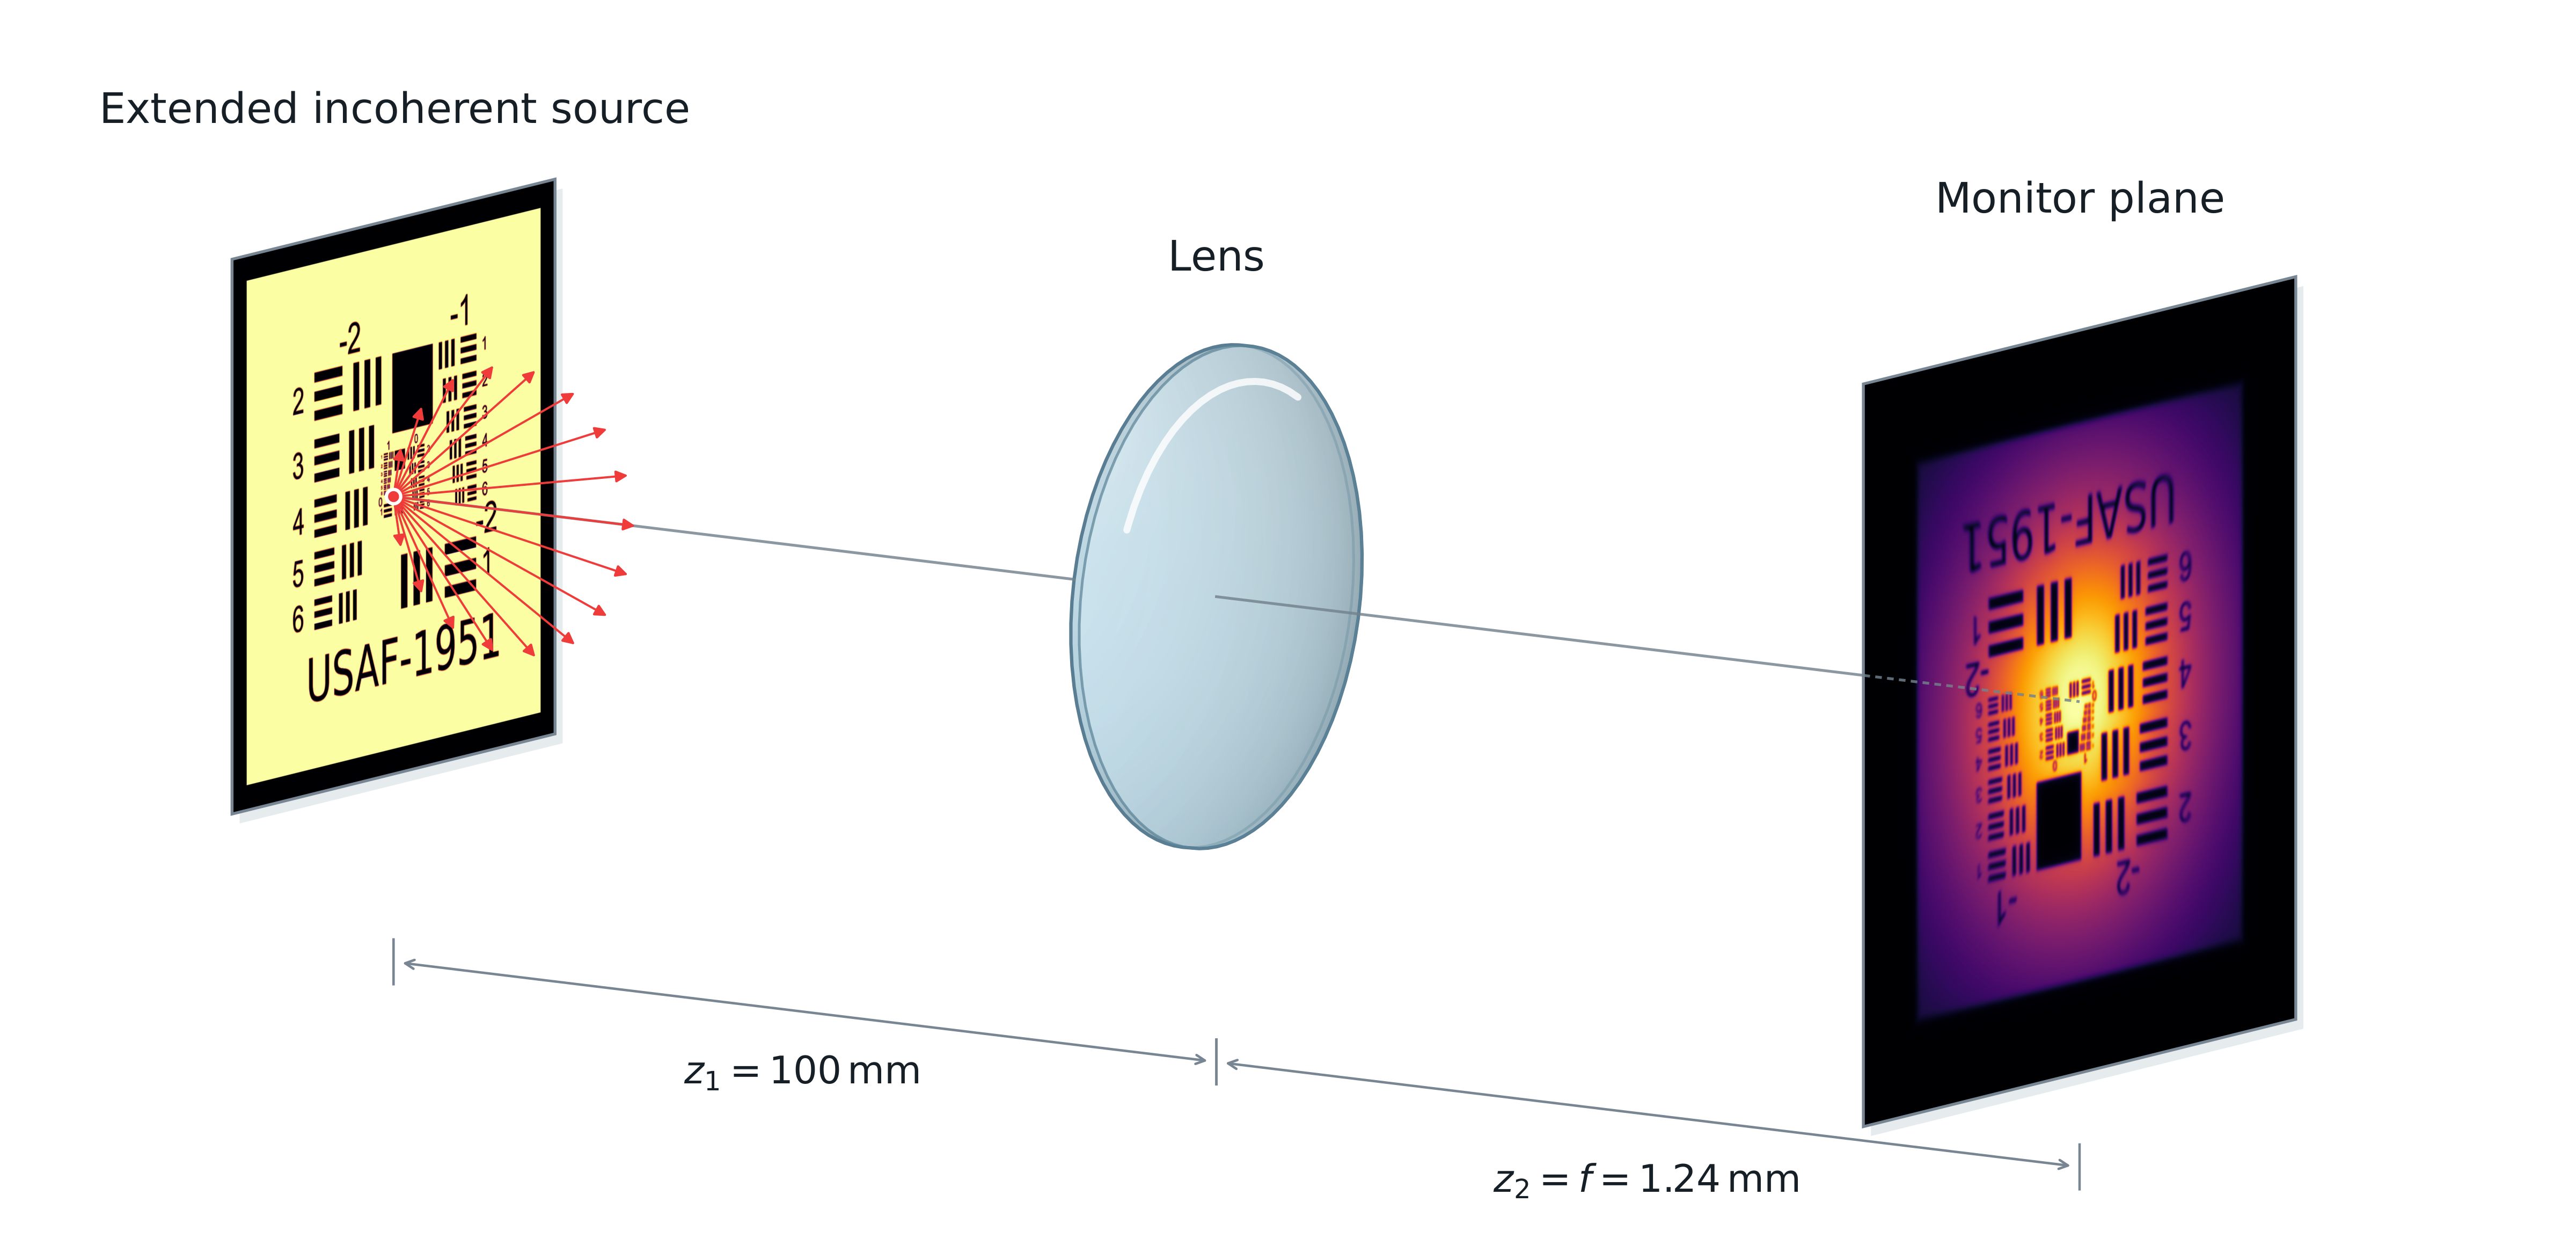

In [6]:
import matplotlib.pyplot as plt
import jax
jax.config.update("jax_enable_x64", True)

import diffractsim
diffractsim.set_backend("JAX")
from diffractsim import IncoherentLightSimulation, ApertureFromFunction, Lens, load_image_as_function
from diffractsim import nm, um, mm, cm
from diffractsim.util.backend_functions import backend as bd

plt.rcParams["figure.dpi"] = 140

## 1. Define the extended source

The source lies at $z=-z_1$, with $z_1=100\,\mathrm{mm}$. The USAF chart fills a $200\,\mathrm{mm}$ square: bright pixels emit with radiance up to $L_*=1\,\mathrm{W\,m^{-2}\,sr^{-1}}$, while dark pixels emit less.

`load_image_as_function` places the chart in source-plane coordinates. With `paraxial=False`, the simulator maps this radiance to the true incident directions, as in Eq. (15):

$$
L_{\mathrm{in}}(\alpha',\beta')=
L_0\!\left(\frac{z_1\alpha'}{c'},\frac{z_1\beta'}{c'}\right),
\qquad c'=\sqrt{1-(\alpha')^2-(\beta')^2}.
$$

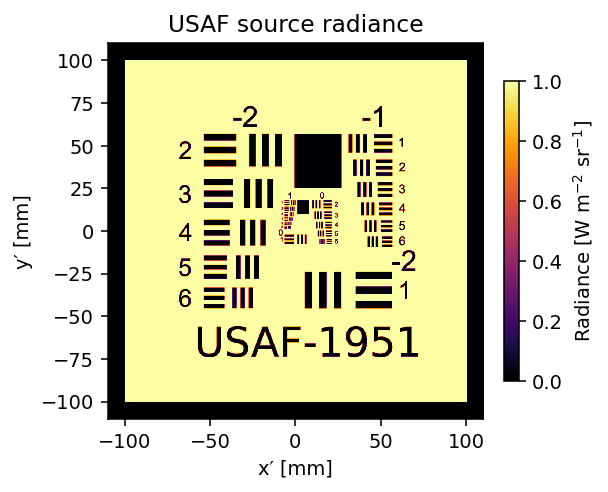

In [7]:
# 1. Load and plot the finite-distance USAF source.
wavelength, z1 = 940*nm, 100*mm
source_width, radiance_scale = 200*mm, 1.0
pupil_width, N = 200*um, 1024
sim = IncoherentLightSimulation(wavelength, pupil_width, pupil_width, N, N)

chart = load_image_as_function("USAF_test_inv.png",
    x_interval=(-source_width/2, source_width/2),
    y_interval=(-source_width/2, source_width/2))

def usaf_source(x, y):
    """Return the chart's radiance, with zero outside its square boundary."""
    return radiance_scale*chart(x, y)

sim.set_illumination_from_plane(usaf_source, z1, paraxial=False,
    angular_samples=2048, source_subpixels=4)

fig, ax = plt.subplots(figsize=(4.2, 3.4), layout="constrained")
sim.plot_illumination_plane(extent_x=1.1*source_width, extent_y=1.1*source_width, units=mm, samples=1025, ax=ax, cmap="inferno", title="USAF source radiance")
plt.show()

## 2. Form the image on the monitor

We place the monitor at $z_2=f$ and calculate the coherent response $H^{\mathrm{mon}}_{z_1,z_2}$ with `model="ASM", sampling="fft"`. The monitor grid resolves the narrow focal response before `get_irradiance` combines it with $L_{\mathrm{in}}$ through Eq. (24). This step includes the angular remapping and the projection onto the flat monitor.

The chief-ray image follows $(x,y)=-(z_2/z_1)(x',y')$. Here $z_2/z_1=0.0124$, so the $200\,\mathrm{mm}$ source spans about $2.48\,\mathrm{mm}$ in the image. Both transverse coordinates reverse naturally. We display the returned irradiance $E(x,y;z_1,z_2)$ directly, keeping that inversion and showing its absolute scale in $\mathrm{mW\,m^{-2}}$.

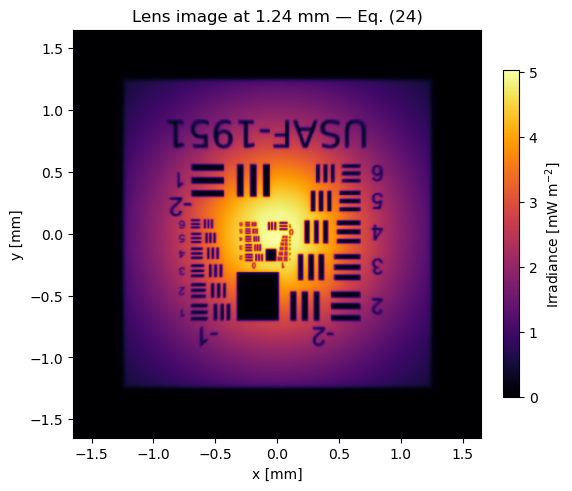

<Axes: title={'center': 'Lens image at 1.24 mm — Eq. (24)'}, xlabel='x [mm]', ylabel='y [mm]'>

In [8]:
# 3. Apply the lens and calculate the monitor irradiance with Eq. (24).
monitor_halfwidth, monitor_samples = 4*mm, 2049
z2 = focal_length = 1.24*mm

def optical_setup(F, z):
    """Apply the lens and propagate to the rectangular monitor."""
    F = F.add(Lens(f=focal_length, radius = 50*um))
    return F.zoom_propagate(z,
        x_interval=[-monitor_halfwidth, monitor_halfwidth],
        y_interval=[-monitor_halfwidth, monitor_halfwidth],
        Nx_mon=monitor_samples, Ny_mon=monitor_samples,
        model="ASM", sampling="fft")

x, y, E = sim.get_irradiance(optical_setup, z2)
sim.plot_irradiance(E, units=mm, irradiance_units=1e-3, cmap="inferno", xlim=(-1.65*mm, 1.65*mm), ylim=(-1.65*mm, 1.65*mm), figsize=(5.7, 4.8),text="Lens image at 1.24 mm — Eq. (24)")